# Proyecto 3 – Aprendizaje no supervisado y reducción de dimensión
**Curso:** Machine Learning · Universidad de Medellín
**Base de datos:** *Sleep Health and Lifestyle Dataset* (Kaggle – `uom190346a`)
**Problema:** clasificación multiclase del **trastorno del sueño** (`Insomnia`, `Sleep Apnea`, `None`)

**Contenido**

| Parte | Tema |
|---|---|
| 1 | Descripción de la base de datos, análisis exploratorio (EDA) y clustering: K-means, jerárquico aglomerativo y DBSCAN |
| 2 | Reducción de dimensión: selección de características (SFFS + wrapper), PCA y LDA, con una red neuronal (MLP) como clasificador |

# PARTE 1

## 1. Descripción de la base de datos

**Fuente:** <https://www.kaggle.com/datasets/uom190346a/sleep-health-and-lifestyle-dataset>

**Dominio del problema:** salud y bienestar. El dataset recoge hábitos de sueño y estilo de vida de 374 personas (edad, ocupación, actividad física, estrés, indicadores cardiovasculares, etc.) junto con el diagnóstico de un trastorno del sueño.

**Utilidad:** identificar qué factores del estilo de vida y de la salud se asocian con el insomnio o la apnea del sueño permite construir sistemas de tamizaje (*screening*) temprano y orientar intervenciones preventivas. Es un problema donde las clases tienen un significado clínico claro, lo que facilita interpretar los resultados de clustering y de selección de características.

**Tipo de problema:** clasificación **multiclase** (3 clases). En la Parte 1 se usa aprendizaje **no supervisado** (la etiqueta solo se emplea para *evaluar* qué tanto los clusters recuperan las clases); en la Parte 2 se usa aprendizaje **supervisado** con reducción de dimensión.

**Variable de salida:** `Sleep Disorder` ∈ {`None`, `Insomnia`, `Sleep Apnea`}.

| Variable | Tipo | Descripción |
|---|---|---|
| `Person ID` | identificador | Identificador de la persona (se descarta, no aporta información) |
| `Gender` | categórica nominal (2) | Male / Female |
| `Age` | numérica discreta | Edad en años |
| `Occupation` | categórica nominal (11) | Profesión de la persona |
| `Sleep Duration` | numérica continua | Horas de sueño por día |
| `Quality of Sleep` | ordinal (1–10) | Calidad del sueño auto-reportada |
| `Physical Activity Level` | numérica | Minutos de actividad física por día |
| `Stress Level` | ordinal (1–10) | Nivel de estrés auto-reportado |
| `BMI Category` | categórica ordinal | Normal / Overweight / Obese |
| `Blood Pressure` | texto `sistólica/diastólica` | Presión arterial (se separa en dos variables numéricas) |
| `Heart Rate` | numérica | Frecuencia cardíaca en reposo (lpm) |
| `Daily Steps` | numérica | Pasos por día |
| `Sleep Disorder` | **salida** categórica (3) | None / Insomnia / Sleep Apnea |

> ⚠️ **Detalle importante:** en el CSV la clase "sin trastorno" está escrita literalmente como el texto `None`. Pandas lo interpreta por defecto como valor faltante (`NaN`). Por eso se carga con `keep_default_na=False`.

In [2]:
# Instalación de dependencias (necesario en Google Colab; en Anaconda ya suelen estar)
!pip install -q mlxtend kagglehub


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_completeness_v_measure, accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics.cluster import contingency_matrix
from sklearn.model_selection import train_test_split, cross_val_score, RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)

In [4]:
CSV = "Sleep_health_and_lifestyle_dataset.csv"

df = pd.read_csv(CSV, keep_default_na=False, na_values=[""])
df.columns = [c.strip() for c in df.columns]
print("Archivo:", CSV)
print("Dimensiones:", df.shape)
df.head()

Archivo: Sleep_health_and_lifestyle_dataset.csv
Dimensiones: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## 2. Análisis exploratorio de datos (EDA)

In [5]:
df.info()
print("\nValores faltantes por columna:\n", df.isna().sum())
print("\nFilas duplicadas (ignorando Person ID):", df.drop(columns="Person ID").duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           374 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB

Valores faltantes por

In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Person ID,374.0,187.50,108.11,1.0,94.25,187.5,280.75,374.0
Age,374.0,42.18,8.67,27.0,35.25,43.0,50.00,59.0
Sleep Duration,374.0,7.13,0.80,5.8,6.40,7.2,7.80,8.5
Quality of Sleep,374.0,7.31,1.20,4.0,6.00,7.0,8.00,9.0
Physical Activity Level,374.0,59.17,20.83,30.0,45.00,60.0,75.00,90.0
Stress Level,374.0,5.39,1.77,3.0,4.00,5.0,7.00,8.0
Heart Rate,374.0,70.17,4.14,65.0,68.00,70.0,72.00,86.0
Daily Steps,374.0,6816.84,1617.92,3000.0,5600.00,7000.0,8000.00,10000.0


In [7]:
# Rango observado por variable numérica (para el análisis de escala)
num_cols = ["Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level",
            "Stress Level", "Heart Rate", "Daily Steps"]
rangos = pd.DataFrame({"min": df[num_cols].min(), "max": df[num_cols].max(),
                       "media": df[num_cols].mean().round(2), "desv. std": df[num_cols].std().round(2),
                       "n° valores únicos": df[num_cols].nunique()})
rangos

,min,max,media,desv. std,n° valores únicos
Age,27.0,59.0,42.18,8.67,31
Sleep Duration,5.8,8.5,7.13,0.80,27
Quality of Sleep,4.0,9.0,7.31,1.20,6
Physical Activity Level,30.0,90.0,59.17,20.83,16
Stress Level,3.0,8.0,5.39,1.77,6
Heart Rate,65.0,86.0,70.17,4.14,19
Daily Steps,3000.0,10000.0,6816.84,1617.92,20


In [8]:
# Variables categóricas y variable de salida
cat_cols = ["Gender", "Occupation", "BMI Category", "Blood Pressure", "Sleep Disorder"]
for c in ["Gender", "BMI Category", "Sleep Disorder"]:
    print(f"--- {c} ---")
    print(df[c].value_counts(), "\n")
print("Ocupaciones:\n", df["Occupation"].value_counts())

--- Gender ---
Gender
Male      189
Female    185
Name: count, dtype: int64 

--- BMI Category ---
BMI Category
Normal           195
Overweight       148
Normal Weight     21
Obese             10
Name: count, dtype: int64 

--- Sleep Disorder ---
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64 

Ocupaciones:
 Occupation
Nurse                   73
Doctor                  71
Engineer                63
Lawyer                  47
Teacher                 40
Accountant              37
Salesperson             32
Scientist                4
Software Engineer        4
Sales Representative     2
Manager                  1
Name: count, dtype: int64


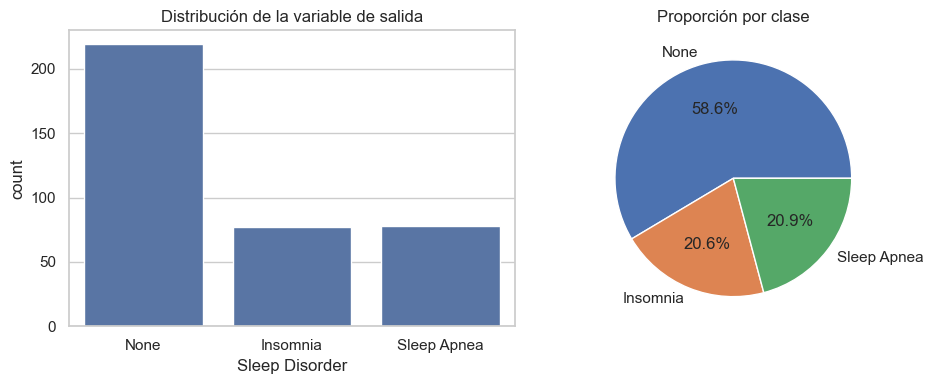

In [9]:
# Distribución de la variable de salida
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
orden = ["None", "Insomnia", "Sleep Apnea"]
sns.countplot(data=df, x="Sleep Disorder", order=orden, ax=ax[0])
ax[0].set_title("Distribución de la variable de salida")
(df["Sleep Disorder"].value_counts(normalize=True)[orden] * 100).plot.pie(autopct="%.1f%%", ax=ax[1], ylabel="")
ax[1].set_title("Proporción por clase")
plt.tight_layout(); plt.show()

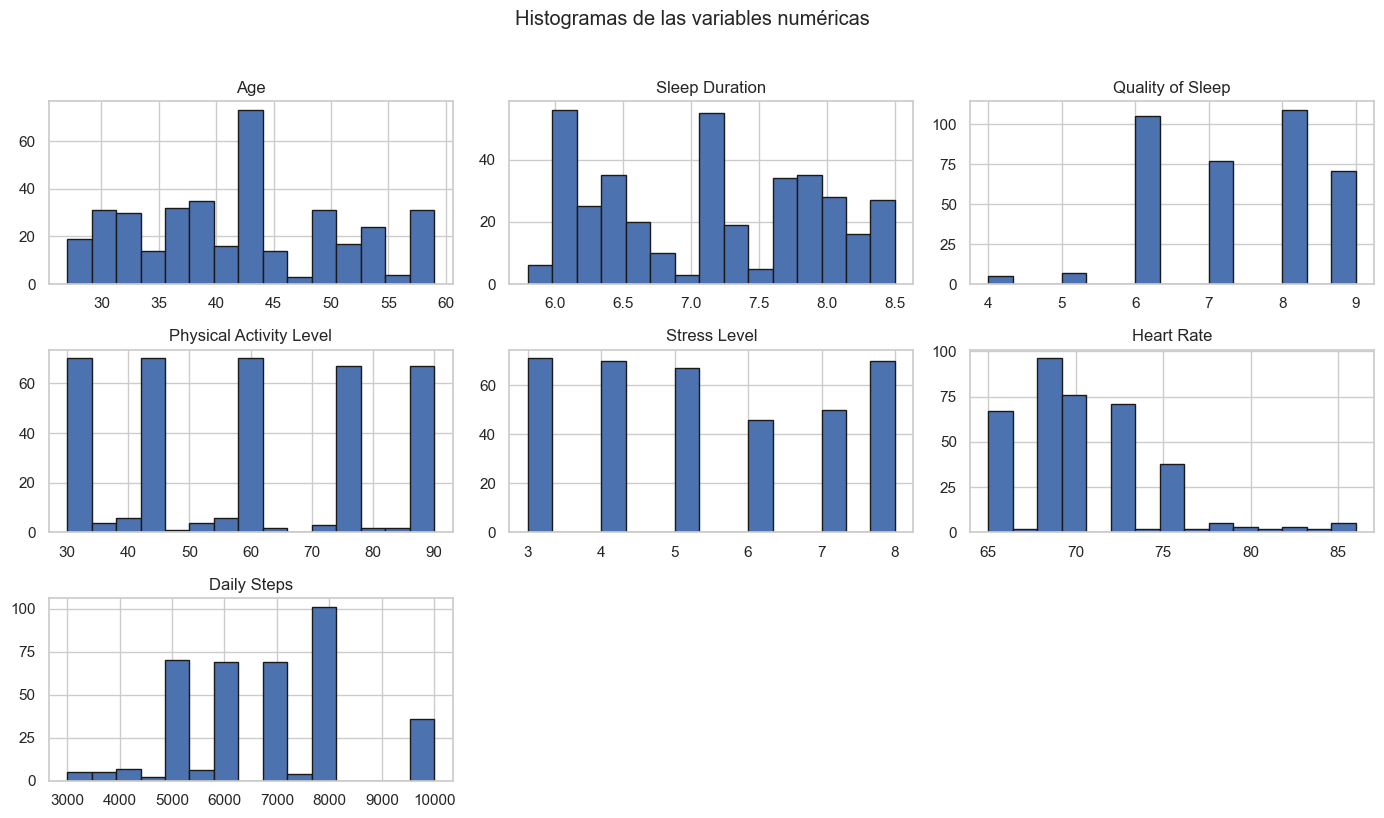

In [10]:
# Histogramas de variables numéricas
df[num_cols].hist(bins=15, figsize=(14, 8), edgecolor="k")
plt.suptitle("Histogramas de las variables numéricas", y=1.02)
plt.tight_layout(); plt.show()

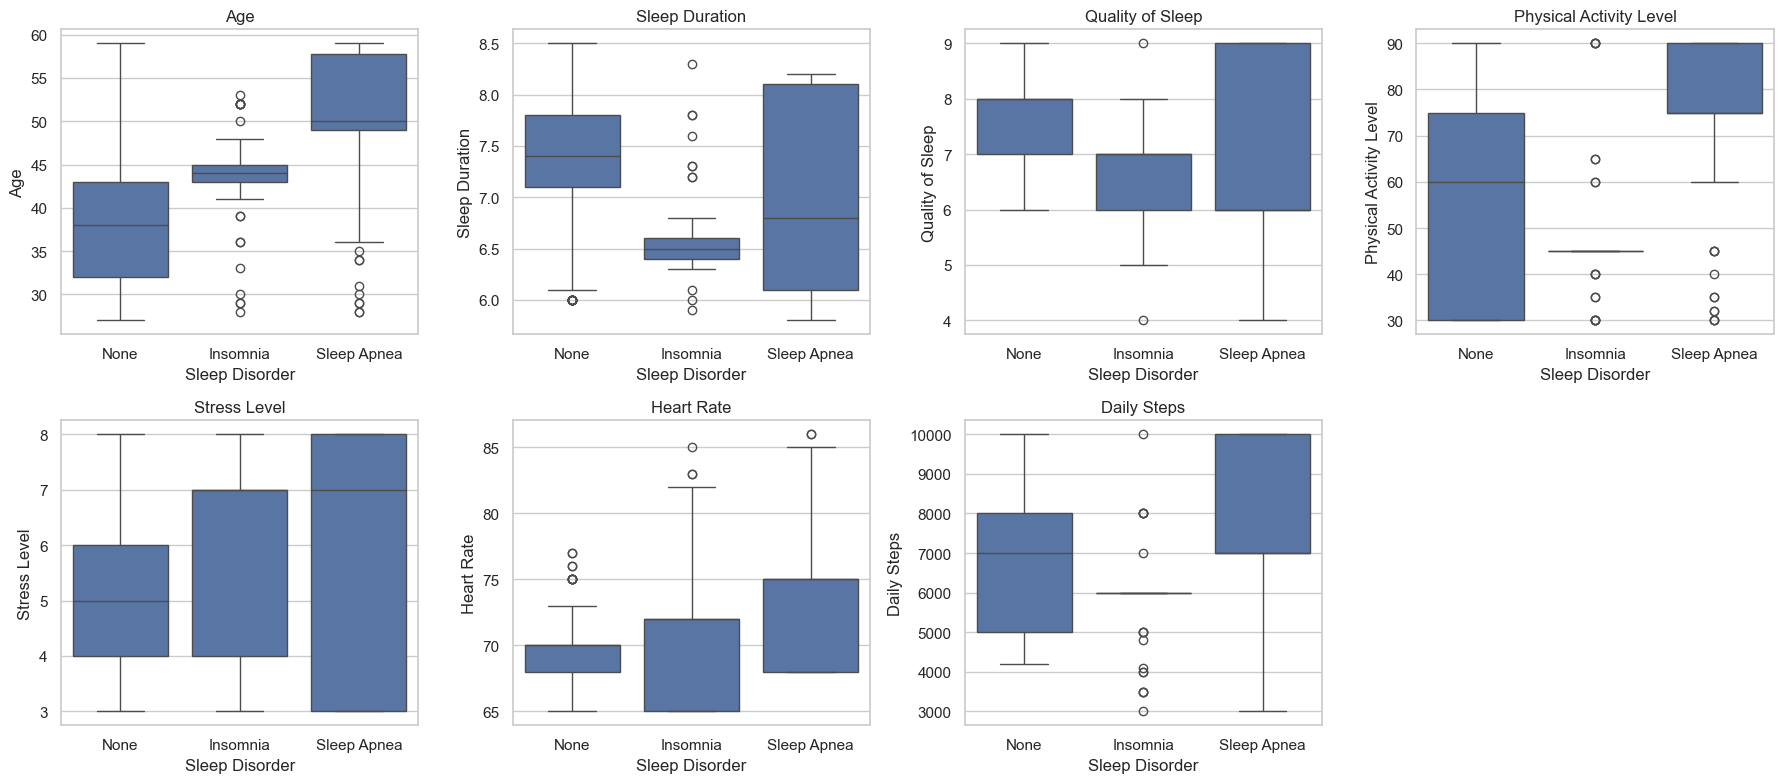

In [11]:
# Variables numéricas vs. clase
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="Sleep Disorder", y=c, order=orden, ax=ax)
    ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

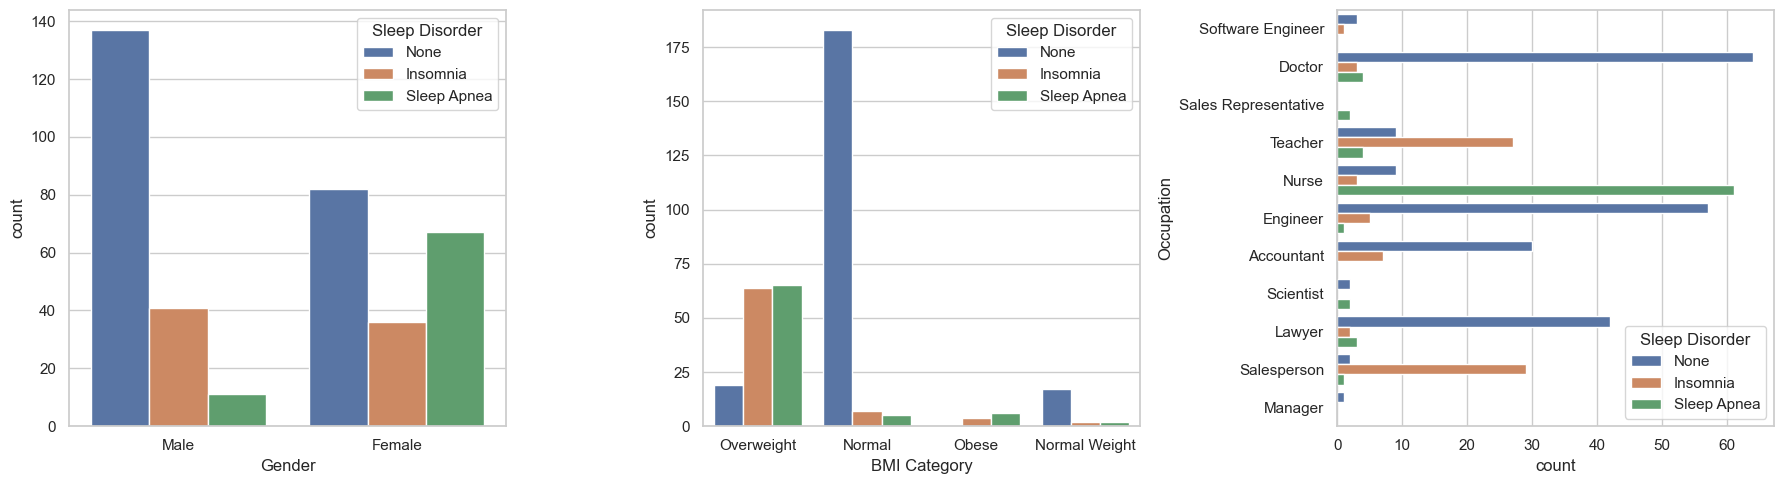

In [12]:
# Variables categóricas vs. clase
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=df, x="Gender", hue="Sleep Disorder", hue_order=orden, ax=axes[0])
sns.countplot(data=df, x="BMI Category", hue="Sleep Disorder", hue_order=orden, ax=axes[1])
sns.countplot(data=df, y="Occupation", hue="Sleep Disorder", hue_order=orden, ax=axes[2])
plt.tight_layout(); plt.show()

### 2.1 Preprocesamiento

- `Person ID` se elimina (identificador).
- `Blood Pressure` (`"126/83"`) se separa en `Systolic` y `Diastolic`.
- `BMI Category`: se unifica `Normal Weight` → `Normal` (en el CSV aparecen ambas etiquetas para la misma categoría) y se codifica como ordinal (Normal = 0, Overweight = 1, Obese = 2).
- `Gender` se codifica binaria; `Occupation` se codifica *one-hot*.
- Todas las variables se **estandarizan** (media 0, desviación 1), ya que K-means, jerárquico, DBSCAN, PCA y las redes neuronales dependen de distancias/escala.

In [13]:
d = df.copy().drop(columns="Person ID")
bp = d["Blood Pressure"].str.split("/", expand=True).astype(int)
d["Systolic"], d["Diastolic"] = bp[0], bp[1]
d["BMI Category"] = d["BMI Category"].replace({"Normal Weight": "Normal"})
d["BMI_ord"] = d["BMI Category"].map({"Normal": 0, "Overweight": 1, "Obese": 2})
d["Gender_Male"] = (d["Gender"] == "Male").astype(int)
occ = pd.get_dummies(d["Occupation"], prefix="Occ", dtype=int)

num_feats = ["Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level",
             "Stress Level", "Heart Rate", "Daily Steps", "Systolic", "Diastolic"]
X = pd.concat([d[num_feats], d[["BMI_ord", "Gender_Male"]], occ], axis=1)

le = LabelEncoder()
y = le.fit_transform(d["Sleep Disorder"])
clases = list(le.classes_)
n_clases = len(clases)
print("Clases:", dict(zip(range(n_clases), clases)))
print("Matriz de características:", X.shape)

X_s = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)  # para clustering

Clases: {0: 'Insomnia', 1: 'None', 2: 'Sleep Apnea'}
Matriz de características: (374, 22)


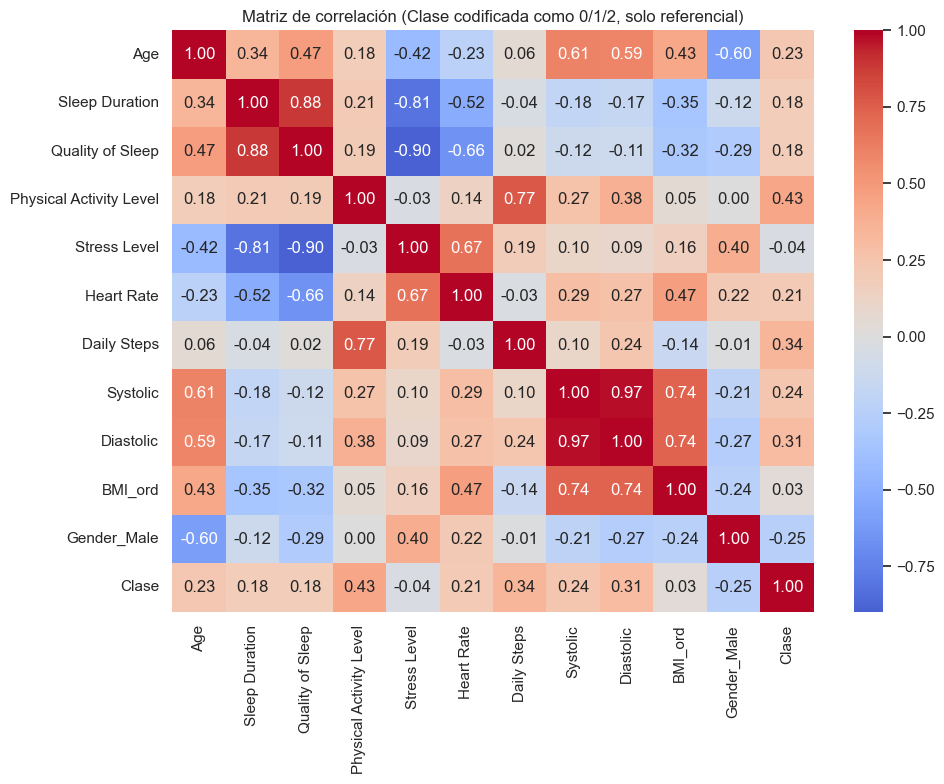

In [14]:
# Correlación entre variables numéricas y con la clase codificada
corr = pd.concat([d[num_feats], d[["BMI_ord", "Gender_Male"]]], axis=1).assign(Clase=y).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación (Clase codificada como 0/1/2, solo referencial)")
plt.tight_layout(); plt.show()

### 2.2 Análisis preliminar

**Lo que se debe observar en las gráficas anteriores (verificar con los resultados de su ejecución):**

- **Tamaño y balance:** ~374 muestras y 3 clases **desbalanceadas** (la clase `None` es la mayoritaria, ≈ 59 %; `Insomnia` y `Sleep Apnea` rondan ≈ 20 % cada una). Por eso conviene usar métricas como *F1 macro* además de la exactitud, y particiones estratificadas.
- **Escalas muy distintas:** `Daily Steps` está en miles (≈ 3 000–10 000) mientras que `Stress Level` está en 3–8 o `Sleep Duration` en 5.8–8.5 h. Sin estandarizar, `Daily Steps` dominaría cualquier distancia euclídea → se justifica el `StandardScaler`.
- **Tipos de variable:** `Quality of Sleep` y `Stress Level` son ordinales con pocos valores distintos; `Age`, `Heart Rate`, `Systolic/Diastolic` son enteras; `Sleep Duration` es la única realmente continua; `Gender`, `Occupation` y `BMI Category` son categóricas.
- **Relaciones con la clase:** se espera que `BMI Category`, `Systolic/Diastolic`, `Age` y `Occupation` separen la clase `Sleep Apnea`, y que `Sleep Duration`/`Quality of Sleep` estén más relacionadas con `Insomnia` y con la ausencia de trastorno. Hay alta correlación entre `Sleep Duration`, `Quality of Sleep` y `Stress Level` (multicolinealidad), lo que anticipa que la reducción de dimensión será útil.
- **Filas repetidas:** muchas filas son idénticas salvo por el ID. Esto hace que el dataset sea "fácil" de clasificar y que DBSCAN encuentre regiones muy densas; hay que tenerlo presente al interpretar métricas altas.
- **Sin valores faltantes** (una vez leída correctamente la clase `None`).

## 3. Aprendizaje no supervisado (clustering)

Se aplican **K-means**, **clustering jerárquico aglomerativo** y **DBSCAN** **sin usar** `Sleep Disorder`. La etiqueta solo se utiliza después para medir qué tan bien los grupos recrean las clases:

- **ARI** (Adjusted Rand Index): 1 = agrupamiento idéntico a las clases, ≈ 0 = aleatorio.
- **NMI**: información mutua normalizada.
- **Homogeneidad / Completitud / V-measure**.
- **Pureza**: fracción de muestras que pertenecen a la clase mayoritaria de su cluster.
- **Silhouette**: métrica interna (no usa etiquetas).

Se prueban distintos números de clusters (k = 2…8), **incluyendo k = 3**, que es el número de clases del problema.

In [15]:
def pureza(y_true, labels):
    cm = contingency_matrix(y_true, labels)
    return cm.max(axis=0).sum() / cm.sum()

def evaluar(X, y_true, labels):
    # Para DBSCAN el ruido (-1) se trata como un grupo más al comparar con las clases
    h, c, v = homogeneity_completeness_v_measure(y_true, labels)
    mask = labels != -1
    k_real = len(set(labels[mask]))
    sil = silhouette_score(X[mask], labels[mask]) if k_real >= 2 and mask.sum() > k_real else np.nan
    return {"ARI": adjusted_rand_score(y_true, labels),
            "NMI": normalized_mutual_info_score(y_true, labels),
            "Homog.": h, "Compl.": c, "V-measure": v,
            "Pureza": pureza(y_true, labels), "Silhouette": sil}

resultados = []   # aquí se acumulan todos los experimentos
Xc = X_s.values

### 3.1 K-means

  File "c:\Users\ASUS\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\ASUS\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\ASUS\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\ASUS\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 1440, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


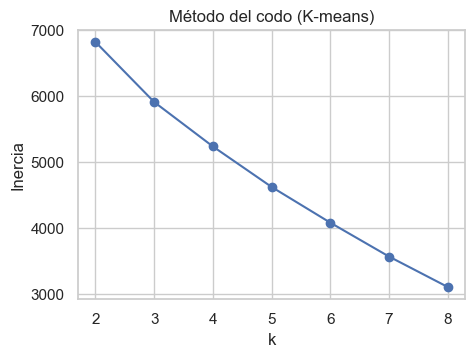

,Config,k,ARI,NMI,Homog.,Compl.,V-measure,Pureza,Silhouette
0,k=2,2,0.591,0.498,0.425,0.601,0.498,0.735,0.240
1,k=3,3,0.269,0.302,0.311,0.294,0.302,0.730,0.277
2,k=4,4,0.388,0.395,0.469,0.341,0.395,0.816,0.308
3,k=5,5,0.282,0.349,0.456,0.282,0.349,0.781,0.371
4,k=6,6,0.305,0.410,0.577,0.318,0.410,0.874,0.427
5,k=7,7,0.225,0.362,0.542,0.272,0.362,0.853,0.493
6,k=8,8,0.202,0.354,0.553,0.261,0.354,0.858,0.558


In [16]:
inercias = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xc)
    inercias.append(km.inertia_)
    resultados.append({"Modelo": "K-means", "Config": f"k={k}", "k": k,
                       "Ruido": 0, **evaluar(Xc, y, km.labels_)})

plt.figure(figsize=(5, 3.5))
plt.plot(range(2, 9), inercias, "o-"); plt.xlabel("k"); plt.ylabel("Inercia")
plt.title("Método del codo (K-means)"); plt.show()

pd.DataFrame([r for r in resultados if r["Modelo"] == "K-means"]).drop(columns=["Modelo", "Ruido"]).round(3)

### 3.2 Clustering jerárquico aglomerativo

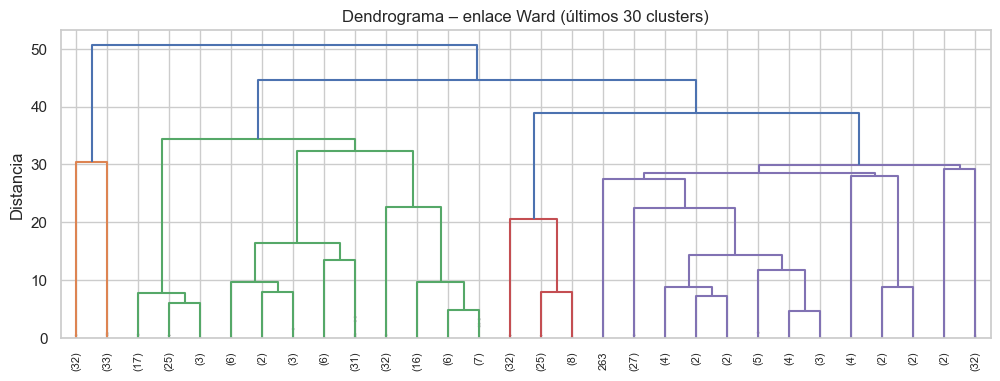

Modelo,Jerárquico (average),Jerárquico (complete),Jerárquico (single),Jerárquico (ward)
k,,,,
2,-0.003,-0.003,-0.003,0.341
3,0.005,0.005,0.005,0.314
4,0.001,0.001,0.001,0.420
5,0.003,0.003,0.003,0.305
6,0.032,0.147,0.147,0.242
7,0.383,0.343,0.279,0.216
8,0.383,0.343,0.270,0.204


In [17]:
# Dendrograma (Ward)
Z = linkage(Xc, method="ward")
plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8, show_contracted=True)
plt.title("Dendrograma – enlace Ward (últimos 30 clusters)"); plt.ylabel("Distancia"); plt.show()

for link in ["ward", "complete", "average", "single"]:
    for k in range(2, 9):
        ag = AgglomerativeClustering(n_clusters=k, linkage=link).fit(Xc)
        resultados.append({"Modelo": f"Jerárquico ({link})", "Config": f"k={k}", "k": k,
                           "Ruido": 0, **evaluar(Xc, y, ag.labels_)})

pd.DataFrame([r for r in resultados if r["Modelo"].startswith("Jerárquico")]) \
  .pivot_table(index="k", columns="Modelo", values="ARI").round(3)

### 3.3 DBSCAN

DBSCAN no recibe el número de clusters: depende de `eps` (radio) y `min_samples`. Se hace una búsqueda en rejilla y se registra cuántos clusters y cuánto ruido produce cada combinación. Para poder compararlo con los otros métodos, el ruido (`-1`) se considera como un grupo adicional al calcular ARI/NMI/pureza.

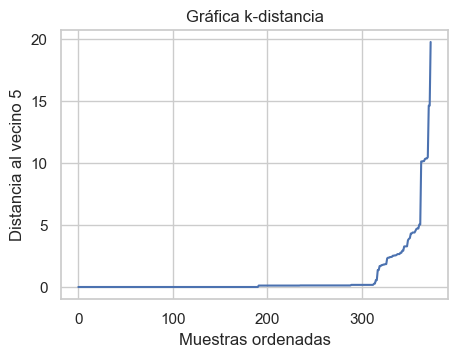

Combinaciones de DBSCAN con al menos 1 cluster: 60


,Modelo,Config,k,Ruido,ARI,NMI,Homog.,Compl.,V-measure,Pureza,Silhouette
31,DBSCAN,"eps=4.5, ms=12",4,22,0.480,0.402,0.422,0.384,0.402,0.805,0.352
30,DBSCAN,"eps=4.5, ms=8",3,18,0.294,0.260,0.233,0.295,0.260,0.730,0.257
28,DBSCAN,"eps=4.5, ms=3",4,9,0.270,0.258,0.228,0.297,0.258,0.730,0.254
29,DBSCAN,"eps=4.5, ms=5",3,13,0.270,0.259,0.226,0.303,0.259,0.730,0.248
21,DBSCAN,"eps=3.5, ms=5",10,22,0.201,0.348,0.577,0.249,0.348,0.864,0.699
20,DBSCAN,"eps=3.5, ms=3",12,11,0.201,0.347,0.585,0.247,0.347,0.869,0.692
22,DBSCAN,"eps=3.5, ms=8",8,35,0.198,0.350,0.566,0.253,0.350,0.861,0.711
23,DBSCAN,"eps=3.5, ms=12",8,35,0.198,0.350,0.566,0.253,0.350,0.861,0.711
24,DBSCAN,"eps=4.0, ms=3",11,11,0.196,0.338,0.561,0.241,0.338,0.856,0.681
26,DBSCAN,"eps=4.0, ms=8",8,28,0.196,0.342,0.553,0.248,0.342,0.850,0.690


In [18]:
# Gráfica k-distancia para guiar la elección de eps
from sklearn.neighbors import NearestNeighbors
ms_ref = 5
dist, _ = NearestNeighbors(n_neighbors=ms_ref).fit(Xc).kneighbors(Xc)
plt.figure(figsize=(5, 3.5))
plt.plot(np.sort(dist[:, -1])); plt.xlabel("Muestras ordenadas"); plt.ylabel(f"Distancia al vecino {ms_ref}")
plt.title("Gráfica k-distancia"); plt.show()

for eps in np.arange(1.0, 8.01, 0.5):
    for ms in [3, 5, 8, 12]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xc)
        k_real = len(set(lab) - {-1})
        if k_real < 1:
            continue
        resultados.append({"Modelo": "DBSCAN", "Config": f"eps={eps:.1f}, ms={ms}", "k": k_real,
                           "Ruido": int((lab == -1).sum()), **evaluar(Xc, y, lab)})

db = pd.DataFrame([r for r in resultados if r["Modelo"] == "DBSCAN"])
print("Combinaciones de DBSCAN con al menos 1 cluster:", len(db))
db.sort_values("ARI", ascending=False).head(10).round(3)

### 3.4 Comparación de modelos y selección del mejor

Se comparan los modelos **con k = 3** (el número real de clases). Para DBSCAN se toma la mejor configuración que produzca exactamente 3 clusters (sin contar ruido); si ninguna lo logra, se reporta la mejor configuración con k más cercano a 3.

In [19]:
R = pd.DataFrame(resultados)

# Mejor configuración por familia con k == n_clases
filas = []
for modelo, g in R.groupby("Modelo"):
    g3 = g[g["k"] == n_clases]
    if len(g3) == 0:                       # DBSCAN puede no tener k exacto
        g3 = g.iloc[(g["k"] - n_clases).abs().argsort()[:1]]
    filas.append(g3.sort_values("ARI", ascending=False).iloc[0])
comp = pd.DataFrame(filas).sort_values("ARI", ascending=False).reset_index(drop=True)
comp.round(3)

,Modelo,Config,k,Ruido,ARI,NMI,Homog.,Compl.,V-measure,Pureza,Silhouette
0,Jerárquico (ward),k=3,3,0,0.314,0.359,0.372,0.347,0.359,0.730,0.269
1,DBSCAN,"eps=4.5, ms=8",3,18,0.294,0.260,0.233,0.295,0.260,0.730,0.257
2,K-means,k=3,3,0,0.269,0.302,0.311,0.294,0.302,0.730,0.277
3,Jerárquico (average),k=3,3,0,0.005,0.019,0.010,0.190,0.019,0.591,0.629
4,Jerárquico (single),k=3,3,0,0.005,0.019,0.010,0.190,0.019,0.591,0.629
5,Jerárquico (complete),k=3,3,0,0.005,0.019,0.010,0.190,0.019,0.591,0.629


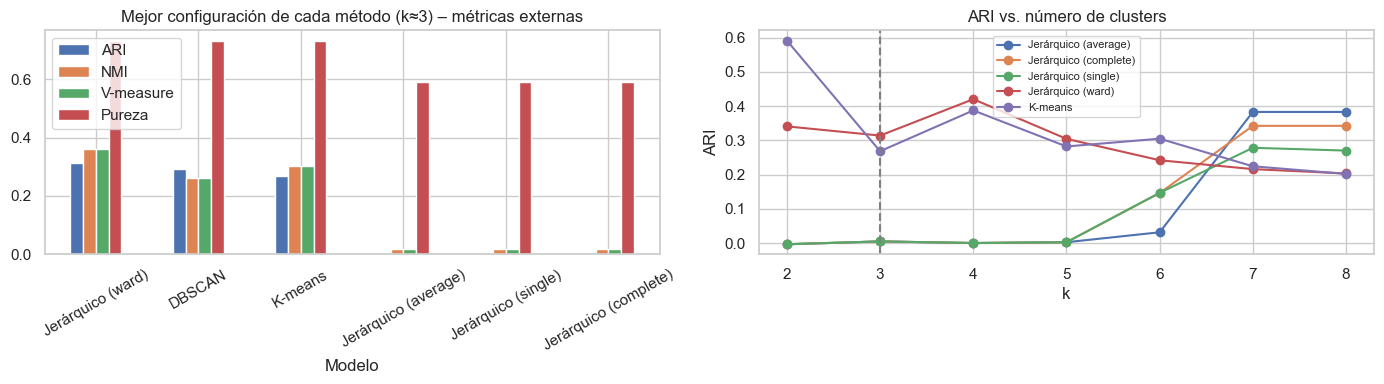

MEJOR MODELO para recrear las 3 clases: Jerárquico (ward)  [k=3]  ARI=0.314  NMI=0.359  Pureza=0.730


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
comp.set_index("Modelo")[["ARI", "NMI", "V-measure", "Pureza"]].plot.bar(ax=ax[0], rot=30)
ax[0].set_title(f"Mejor configuración de cada método (k≈{n_clases}) – métricas externas")

for m, g in R.groupby("Modelo"):
    if m != "DBSCAN":
        ax[1].plot(g["k"], g["ARI"], "o-", label=m)
ax[1].axvline(n_clases, color="gray", ls="--"); ax[1].set_xlabel("k"); ax[1].set_ylabel("ARI")
ax[1].set_title("ARI vs. número de clusters"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

mejor = comp.iloc[0]
print(f"MEJOR MODELO para recrear las {n_clases} clases: {mejor['Modelo']}  [{mejor['Config']}]  "
      f"ARI={mejor['ARI']:.3f}  NMI={mejor['NMI']:.3f}  Pureza={mejor['Pureza']:.3f}")

Clusters (filas) vs. clases reales (columnas):
Clase real  Insomnia  None  Sleep Apnea
Cluster                                
0                 64    75           16
1                  1     5           59
2                 12   139            3


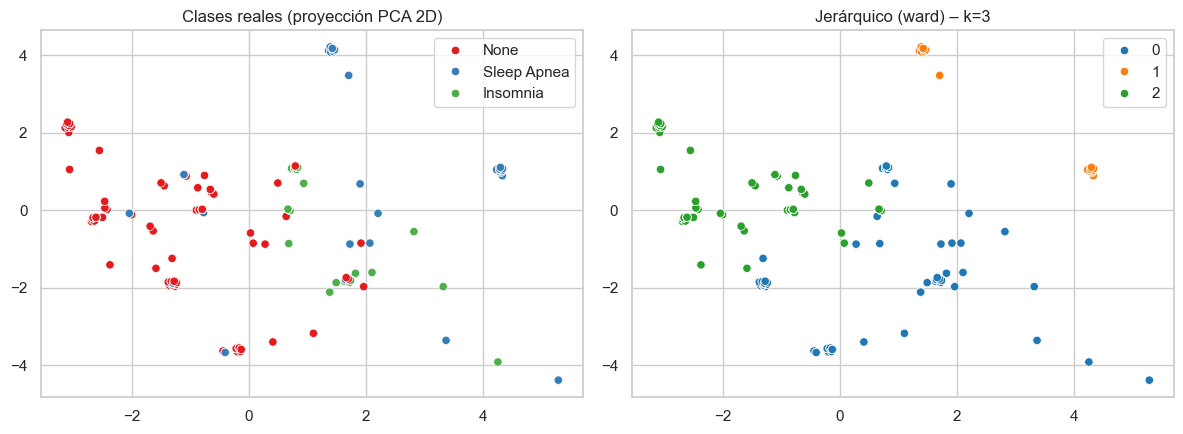

In [21]:
# Reconstruir las etiquetas del mejor modelo y compararlas con las clases reales
def etiquetas(modelo, config):
    if modelo == "K-means":
        return KMeans(n_clusters=int(config.split("=")[1]), n_init=20, random_state=SEED).fit_predict(Xc)
    if modelo.startswith("Jerárquico"):
        return AgglomerativeClustering(n_clusters=int(config.split("=")[1]),
                                       linkage=modelo.split("(")[1][:-1]).fit_predict(Xc)
    eps = float(config.split(",")[0].split("=")[1]); ms = int(config.split("ms=")[1])
    return DBSCAN(eps=eps, min_samples=ms).fit_predict(Xc)

lab_best = etiquetas(mejor["Modelo"], mejor["Config"])
print("Clusters (filas) vs. clases reales (columnas):")
print(pd.crosstab(pd.Series(lab_best, name="Cluster"), pd.Series(le.inverse_transform(y), name="Clase real")))

p2 = PCA(2, random_state=SEED).fit_transform(Xc)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(x=p2[:, 0], y=p2[:, 1], hue=le.inverse_transform(y), ax=ax[0], palette="Set1")
ax[0].set_title("Clases reales (proyección PCA 2D)")
sns.scatterplot(x=p2[:, 0], y=p2[:, 1], hue=lab_best, ax=ax[1], palette="tab10")
ax[1].set_title(f"{mejor['Modelo']} – {mejor['Config']}")
plt.tight_layout(); plt.show()

**Conclusión de la Parte 1 (redactar con sus resultados):** indique (i) qué método obtuvo el mayor ARI/NMI/pureza con k = 3, (ii) si aumentar k mejora la pureza a costa de perder correspondencia con las clases, (iii) cómo se comportó DBSCAN (cuánto ruido, cuántos clusters, sensibilidad a `eps`) y (iv) por qué el clustering puro no recupera perfectamente las clases (variables irrelevantes, clases solapadas, desbalance, escalas/tipos mixtos).

# PARTE 2 – Reducción de dimensión y clasificación supervisada

**Esquema experimental**

- Partición **estratificada** 80 % entrenamiento / 20 % prueba (`random_state=42`).
- **Toda** la selección/transformación (escalado, SFFS, PCA, LDA) se ajusta **solo con el entrenamiento**; el conjunto de prueba se usa una única vez para reportar el resultado final.
- La elección de la mejor opción (wrapper, dimensión) se hace por **validación cruzada** sobre el entrenamiento, no con el test.
- Clasificador final: **Red neuronal (MLPClassifier)**.
- Métricas: exactitud y *F1 macro* (las clases están desbalanceadas).

In [22]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_tr.shape, " Test:", X_te.shape)
print("Distribución train:", np.bincount(y_tr), " test:", np.bincount(y_te))

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

def nuevo_mlp():
    return MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu", alpha=1e-3,
                         max_iter=3000, early_stopping=False, random_state=SEED)

# Línea base: todas las características
base = make_pipeline(StandardScaler(), nuevo_mlp())
cv_base = cross_val_score(base, X_tr, y_tr, cv=cv, scoring="accuracy", n_jobs=-1)
base.fit(X_tr, y_tr)
pred = base.predict(X_te)
res_base = {"Método": "Todas las características", "Dim": X.shape[1],
            "CV acc": cv_base.mean(), "Test acc": accuracy_score(y_te, pred),
            "Test F1-macro": f1_score(y_te, pred, average="macro")}
print(res_base)

Train: (299, 22)  Test: (75, 22)
Distribución train: [ 62 175  62]  test: [15 44 16]
{'Método': 'Todas las características', 'Dim': 22, 'CV acc': np.float64(0.8945762711864406), 'Test acc': 0.9466666666666667, 'Test F1-macro': 0.9214211076280042}


## 1. Selección de características: wrapper + SFFS

**SFFS** (*Sequential Floating Forward Selection*) parte de un conjunto vacío, añade en cada paso la característica que más mejora el criterio y, tras cada adición, intenta **eliminar** (flotante) características previamente elegidas si eso mejora el criterio.

El **wrapper** es el modelo cuyo desempeño en validación cruzada guía la búsqueda. Se prueban tres alternativas (KNN, árbol de decisión y regresión logística) y se compara cuál produce el mejor subconjunto para la **red neuronal**.

In [23]:
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

scaler = StandardScaler().fit(X_tr)
X_tr_s = pd.DataFrame(scaler.transform(X_tr), columns=X.columns, index=X_tr.index)
X_te_s = pd.DataFrame(scaler.transform(X_te), columns=X.columns, index=X_te.index)

wrappers = {
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "Regresión logística": LogisticRegression(max_iter=2000),
}

sffs_res, sffs_sel = [], {}
for nombre, est in wrappers.items():
    sfs = SFS(est, k_features="best", forward=True, floating=True,
              scoring="accuracy", cv=5, n_jobs=-1)
    sfs.fit(X_tr_s, y_tr)
    feats = list(sfs.k_feature_names_)
    sffs_sel[nombre] = (feats, sfs)

    # Evaluación del subconjunto con el CLASIFICADOR FINAL (MLP)
    pipe = make_pipeline(StandardScaler(), nuevo_mlp())
    cv_sc = cross_val_score(pipe, X_tr[feats], y_tr, cv=cv, scoring="accuracy", n_jobs=-1)
    pipe.fit(X_tr[feats], y_tr)
    p = pipe.predict(X_te[feats])
    sffs_res.append({"Wrapper": nombre, "Dim": len(feats), "Acc wrapper (CV)": sfs.k_score_,
                     "MLP CV acc": cv_sc.mean(), "MLP Test acc": accuracy_score(y_te, p),
                     "MLP Test F1-macro": f1_score(y_te, p, average="macro"), "Características": feats})
    print(f"{nombre}: {len(feats)} características -> {feats}")

sffs_df = pd.DataFrame(sffs_res).sort_values("MLP CV acc", ascending=False).reset_index(drop=True)
sffs_df.drop(columns="Características").round(3)

KNN (k=5): 7 características -> ['Daily Steps', 'Systolic', 'Diastolic', 'Occ_Accountant', 'Occ_Nurse', 'Occ_Salesperson', 'Occ_Software Engineer']
Árbol de decisión: 8 características -> ['Age', 'Sleep Duration', 'Stress Level', 'Systolic', 'Occ_Accountant', 'Occ_Engineer', 'Occ_Nurse', 'Occ_Software Engineer']
Regresión logística: 13 características -> ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Systolic', 'Diastolic', 'Gender_Male', 'Occ_Accountant', 'Occ_Engineer', 'Occ_Sales Representative', 'Occ_Salesperson']


,Wrapper,Dim,Acc wrapper (CV),MLP CV acc,MLP Test acc,MLP Test F1-macro
0,Regresión logística,13,0.910,0.898,0.973,0.957
1,Árbol de decisión,8,0.906,0.890,0.933,0.904
2,KNN (k=5),7,0.900,0.883,0.907,0.859


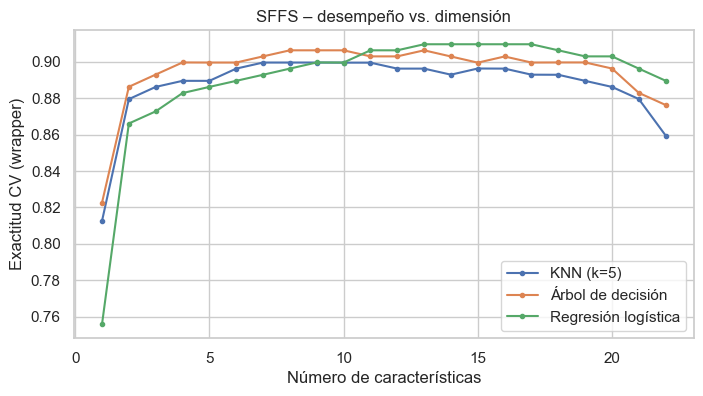

In [24]:
# Curvas de SFFS: desempeño del wrapper vs. número de características
fig, ax = plt.subplots(figsize=(8, 4))
for nombre, (feats, sfs) in sffs_sel.items():
    ks = sorted(sfs.get_metric_dict().keys())
    ax.plot(ks, [sfs.get_metric_dict()[k]["avg_score"] for k in ks], "o-", ms=3, label=nombre)
ax.set_xlabel("Número de características"); ax.set_ylabel("Exactitud CV (wrapper)")
ax.set_title("SFFS – desempeño vs. dimensión"); ax.legend(); plt.show()

Mejor wrapper (según CV del MLP): Regresión logística  ->  13 características
['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Systolic', 'Diastolic', 'Gender_Male', 'Occ_Accountant', 'Occ_Engineer', 'Occ_Sales Representative', 'Occ_Salesperson']

               precision    recall  f1-score   support

    Insomnia       0.93      0.93      0.93        15
        None       1.00      1.00      1.00        44
 Sleep Apnea       0.94      0.94      0.94        16

    accuracy                           0.97        75
   macro avg       0.96      0.96      0.96        75
weighted avg       0.97      0.97      0.97        75



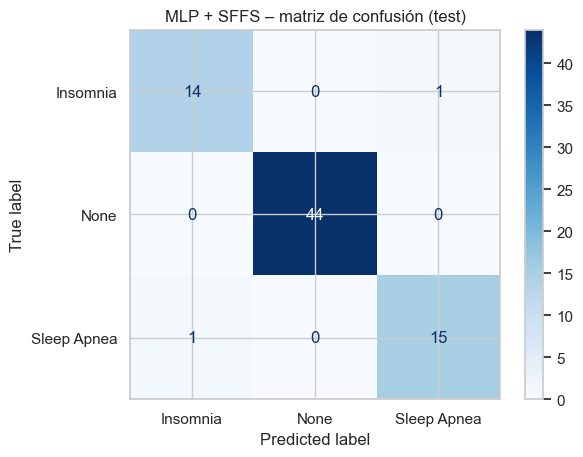

In [25]:
mejor_w = sffs_df.iloc[0]
feats_best = mejor_w["Características"]
print(f"Mejor wrapper (según CV del MLP): {mejor_w['Wrapper']}  ->  {len(feats_best)} características")
print(feats_best)

final_sffs = make_pipeline(StandardScaler(), nuevo_mlp()).fit(X_tr[feats_best], y_tr)
p = final_sffs.predict(X_te[feats_best])
print("\n", classification_report(y_te, p, target_names=clases))
ConfusionMatrixDisplay.from_predictions(y_te, p, display_labels=clases, cmap="Blues")
plt.title("MLP + SFFS – matriz de confusión (test)"); plt.show()

res_sffs = {"Método": f"SFFS ({mejor_w['Wrapper']})", "Dim": len(feats_best),
            "CV acc": mejor_w["MLP CV acc"], "Test acc": accuracy_score(y_te, p),
            "Test F1-macro": f1_score(y_te, p, average="macro")}

## 2. Variables más importantes (discriminantes)

Se combinan dos fuentes de evidencia: (a) las características elegidas por SFFS, y cuántos wrappers las seleccionan (consistencia), y (b) la **importancia por permutación** de la red neuronal entrenada con todas las variables.

,Veces seleccionada (de 3 wrappers),En el mejor wrapper
Systolic,3,True
Occ_Accountant,3,True
Diastolic,2,True
Occ_Nurse,2,False
Occ_Software Engineer,2,False
Occ_Salesperson,2,True
Age,2,True
Sleep Duration,2,True
Occ_Engineer,2,True
Stress Level,2,True


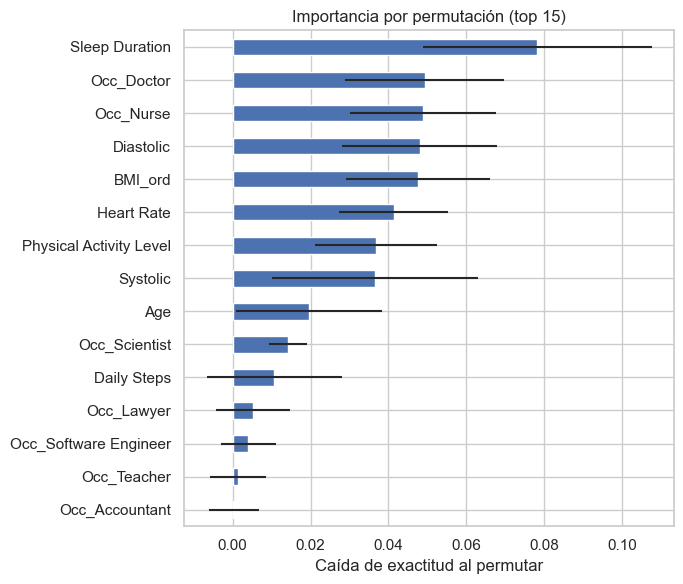

In [26]:
# (a) Frecuencia de selección entre wrappers
freq = pd.Series([f for feats, _ in sffs_sel.values() for f in feats]).value_counts()
freq = freq.rename("Veces seleccionada (de 3 wrappers)").to_frame()
freq["En el mejor wrapper"] = freq.index.isin(feats_best)
display(freq)

# (b) Importancia por permutación (MLP con todas las variables, evaluada en test)
pi = permutation_importance(base, X_te, y_te, n_repeats=30, random_state=SEED, scoring="accuracy")
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(7, 6))
imp.head(15)[::-1].plot.barh(xerr=pd.Series(pi.importances_std, index=X.columns)[imp.head(15).index][::-1])
plt.xlabel("Caída de exactitud al permutar"); plt.title("Importancia por permutación (top 15)")
plt.tight_layout(); plt.show()

**Interpretación (completar con sus resultados):** liste las variables que SFFS selecciona de forma consistente y explique, con ayuda de los boxplots del EDA, *por qué* discriminan (p. ej., qué valores de presión arterial, IMC, edad, duración o calidad del sueño caracterizan a cada trastorno). Las variables que ningún wrapper selecciona y que además tienen importancia por permutación ≈ 0 se consideran redundantes o poco informativas.

## 3. Reducción de dimensión con PCA

PCA es **no supervisado**: proyecta sobre las direcciones de máxima varianza. Se evalúa el MLP para cada número de componentes `d = 1,…,p`. El escalado y PCA van dentro del `Pipeline`, de modo que en cada fold se ajustan únicamente con los datos de entrenamiento de ese fold.

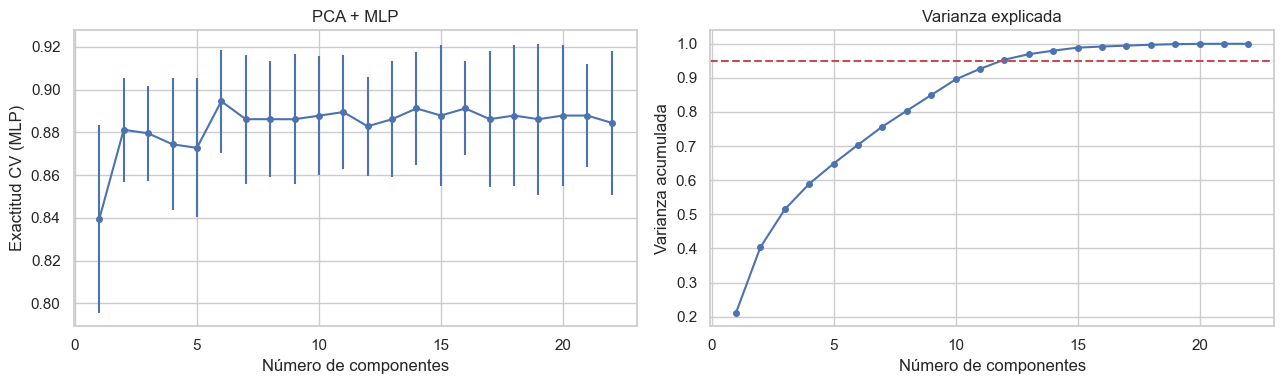

Mejor dimensión PCA (CV): 6  | varianza explicada: 70.38%
Test acc=0.933  F1-macro=0.901


,Componentes,CV acc,CV std
0,1,0.840,0.044
1,2,0.881,0.024
2,3,0.880,0.022
3,4,0.874,0.031
4,5,0.873,0.033
5,6,0.895,0.024
6,7,0.886,0.030
7,8,0.886,0.027
8,9,0.886,0.030
9,10,0.888,0.028


In [27]:
p_total = X.shape[1]
pca_res = []
for dcomp in range(1, p_total + 1):
    pipe = make_pipeline(StandardScaler(), PCA(n_components=dcomp, random_state=SEED), nuevo_mlp())
    sc = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="accuracy", n_jobs=-1)
    pca_res.append({"Componentes": dcomp, "CV acc": sc.mean(), "CV std": sc.std()})
pca_df = pd.DataFrame(pca_res)

pca_full = make_pipeline(StandardScaler(), PCA(random_state=SEED)).fit(X_tr)
var_cum = np.cumsum(pca_full[-1].explained_variance_ratio_)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].errorbar(pca_df["Componentes"], pca_df["CV acc"], yerr=pca_df["CV std"], fmt="o-", ms=4)
ax[0].set_xlabel("Número de componentes"); ax[0].set_ylabel("Exactitud CV (MLP)"); ax[0].set_title("PCA + MLP")
ax[1].plot(range(1, p_total + 1), var_cum, "o-", ms=4); ax[1].axhline(0.95, color="r", ls="--")
ax[1].set_xlabel("Número de componentes"); ax[1].set_ylabel("Varianza acumulada"); ax[1].set_title("Varianza explicada")
plt.tight_layout(); plt.show()

d_pca = int(pca_df.loc[pca_df["CV acc"].idxmax(), "Componentes"])
pipe_pca = make_pipeline(StandardScaler(), PCA(n_components=d_pca, random_state=SEED), nuevo_mlp()).fit(X_tr, y_tr)
p = pipe_pca.predict(X_te)
print(f"Mejor dimensión PCA (CV): {d_pca}  | varianza explicada: {var_cum[d_pca-1]:.2%}")
print(f"Test acc={accuracy_score(y_te, p):.3f}  F1-macro={f1_score(y_te, p, average='macro'):.3f}")
res_pca = {"Método": "PCA", "Dim": d_pca, "CV acc": pca_df["CV acc"].max(),
           "Test acc": accuracy_score(y_te, p), "Test F1-macro": f1_score(y_te, p, average="macro")}
pca_df.round(3)

## 4. Reducción de dimensión con LDA

LDA es **supervisado**: busca las direcciones que maximizan la separación entre clases. El número máximo de componentes es `min(n_clases − 1, n_características)` = **2** para este problema (3 clases), por lo que solo se pueden evaluar 1 y 2 dimensiones.

Mejor dimensión LDA (CV): 2
Test acc=0.947  F1-macro=0.929


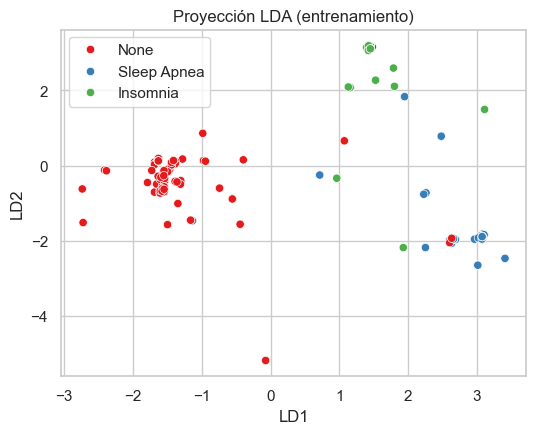

,Componentes,CV acc,CV std
0,1,0.849,0.058
1,2,0.896,0.021


In [28]:
lda_res = []
for dcomp in range(1, min(n_clases - 1, p_total) + 1):
    pipe = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=dcomp), nuevo_mlp())
    sc = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="accuracy", n_jobs=-1)
    lda_res.append({"Componentes": dcomp, "CV acc": sc.mean(), "CV std": sc.std()})
lda_df = pd.DataFrame(lda_res)

d_lda = int(lda_df.loc[lda_df["CV acc"].idxmax(), "Componentes"])
pipe_lda = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=d_lda), nuevo_mlp()).fit(X_tr, y_tr)
p = pipe_lda.predict(X_te)
print(f"Mejor dimensión LDA (CV): {d_lda}")
print(f"Test acc={accuracy_score(y_te, p):.3f}  F1-macro={f1_score(y_te, p, average='macro'):.3f}")
res_lda = {"Método": "LDA", "Dim": d_lda, "CV acc": lda_df["CV acc"].max(),
           "Test acc": accuracy_score(y_te, p), "Test F1-macro": f1_score(y_te, p, average="macro")}

# Proyección LDA 2D del conjunto de entrenamiento
lda2 = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2)).fit(X_tr, y_tr)
Z2 = lda2.transform(X_tr)
plt.figure(figsize=(6, 4.5))
sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=le.inverse_transform(y_tr), palette="Set1")
plt.xlabel("LD1"); plt.ylabel("LD2"); plt.title("Proyección LDA (entrenamiento)"); plt.show()
lda_df.round(3)

## 5. Comparación final y conclusiones

,Método,Dim,CV acc,Test acc,Test F1-macro
0,Todas las características,22,0.895,0.947,0.921
1,SFFS (Regresión logística),13,0.898,0.973,0.957
2,PCA,6,0.895,0.933,0.901
3,LDA,2,0.896,0.947,0.929


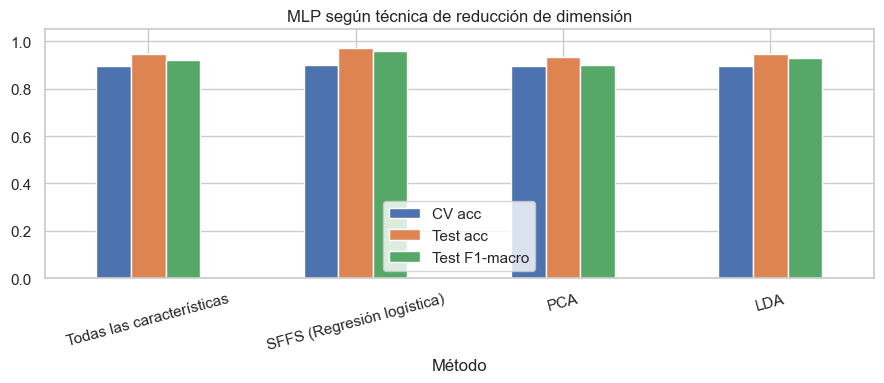

Mejor técnica según validación cruzada: SFFS (Regresión logística) con 13 dimensión(es).


In [29]:
final = pd.DataFrame([res_base, res_sffs, res_pca, res_lda])
display(final.round(3))

final.set_index("Método")[["CV acc", "Test acc", "Test F1-macro"]].plot.bar(rot=15, figsize=(9, 4))
plt.ylim(0, 1.05); plt.title("MLP según técnica de reducción de dimensión"); plt.tight_layout(); plt.show()

mejor_final = final.sort_values(["CV acc", "Dim"], ascending=[False, True]).iloc[0]
print(f"Mejor técnica según validación cruzada: {mejor_final['Método']} con {int(mejor_final['Dim'])} dimensión(es).")

### Conclusiones (redactar con sus resultados)

1. **SFFS:** número de características que conserva, cuáles son y si el MLP mejora o iguala la línea base con menos variables.
2. **Variables discriminantes:** las más importantes y su interpretación clínica/de estilo de vida.
3. **PCA:** dimensión con la que se obtienen los mejores resultados y varianza que explica. Recuerde que PCA no usa la etiqueta, así que no garantiza separar las clases.
4. **LDA:** con solo 1–2 dimensiones (límite teórico = clases − 1) qué tanto se conserva el desempeño.
5. **Advertencias metodológicas:** dataset pequeño (374 filas, con muchas filas repetidas) → las métricas pueden ser optimistas y tener varianza alta entre particiones; por eso se reporta validación cruzada repetida y no solo el test.